In [44]:
# Projekt 10 – Bodenatmung
# Modellvalidierung

# Pakete laden
library(boot)   #Funtkion fuer Cross validation
library(lmtest) #Breusch-Pagan-test -> "Tests zur Pruefung von Heteroskedastizitaet" 
library(zoo)

# Daten einlesen
hainich.data <- read.csv("hainich.csv", sep=";")
data_clean <- na.omit(hainich.data)

#bester model und diss_model: bester model ist vorzuziehen, bessere Werte und sparsamer
# auch model_diss ohne kolinearität ist nicht besser
# model mit interaktion 1 am schlechtesten, aber auch model mit interaktion 2 nicht besser als best model

# model aus regsubset
best_model_regsubset <- lm(log(soil.res) ~ I(lmoi^2) * soilc0 +
    I(soilc0^2) + I(temp.15^2) + I(rootdw0^2) + I(litter.d^2), data = data_clean)

# model mit Multikollinearität
model_multi <- lm(log(soil.res) ~ soiln0 + I(soiln0^2) + litdoc + temp.15 + I(temp.15^2) + 
    I(rootc5^2), data = data_clean)
#besser in LooCV und shapiro und breusch test, aber schlechterer scale plot und weniger sparsam als bester_model

# nur signifikante Variablen von regsubset
bester_model <- lm(log(soil.res) ~ I(temp.15^2) + I(litter.d^2), data = data_clean)
bester_model_wI <- lm(log(soil.res) ~ temp.15 + I(temp.15^2) + litter.d + I(litter.d^2), data = data_clean)

#anshs Modelle
full_model <- lm(log(soil.res) ~ lmoi + smoi + rootdw0 + litdoc + soiln0 + sno35,
                 data = data_clean)

model2 <- lm(log(soil.res) ~ lmoi + smoi + I(smoi^2) + rootdw0 + litdoc + soiln0 + sno35,
             data = data_clean)

# Temperatur, Feuchtigkeit, Wurzelbiomasse und Kohlenstoffgehalt
model_diss <- lm(log(soil.res) ~ I(rootdw0^2) + soilc0 + I(temp.15^2) + lmoi, data = data_clean)
#multikollinerität zwischen rootdw0 und temp.15
model_diss_kol <- lm(log(soil.res) ~ soilc0 + I(temp.15^2) + lmoi, data = hainich.data)

#interaktionen bei model_diss
#lmoi * soilc0 (I1)
#temp.15^2 * lmoi (I2)

model_diss_I1 <- lm(log(soil.res) ~ I(temp.15^2) + lmoi * soilc0, data = hainich.data)
model_diss_I2 <- lm(log(soil.res) ~ soilc0 + temp.15 + I(temp.15^2) * lmoi, data = hainich.data)

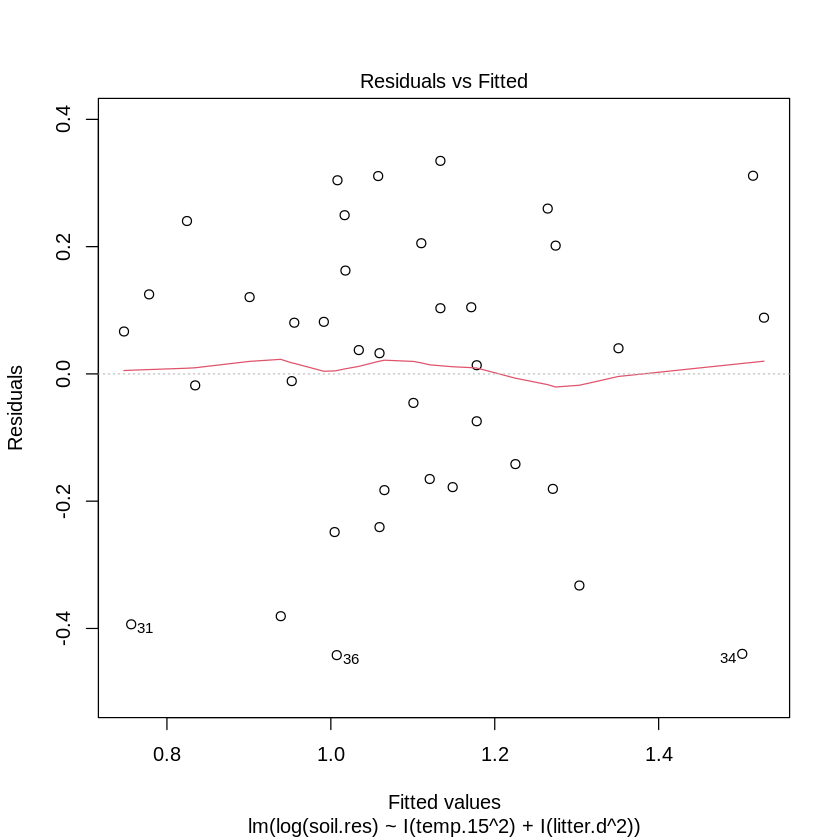

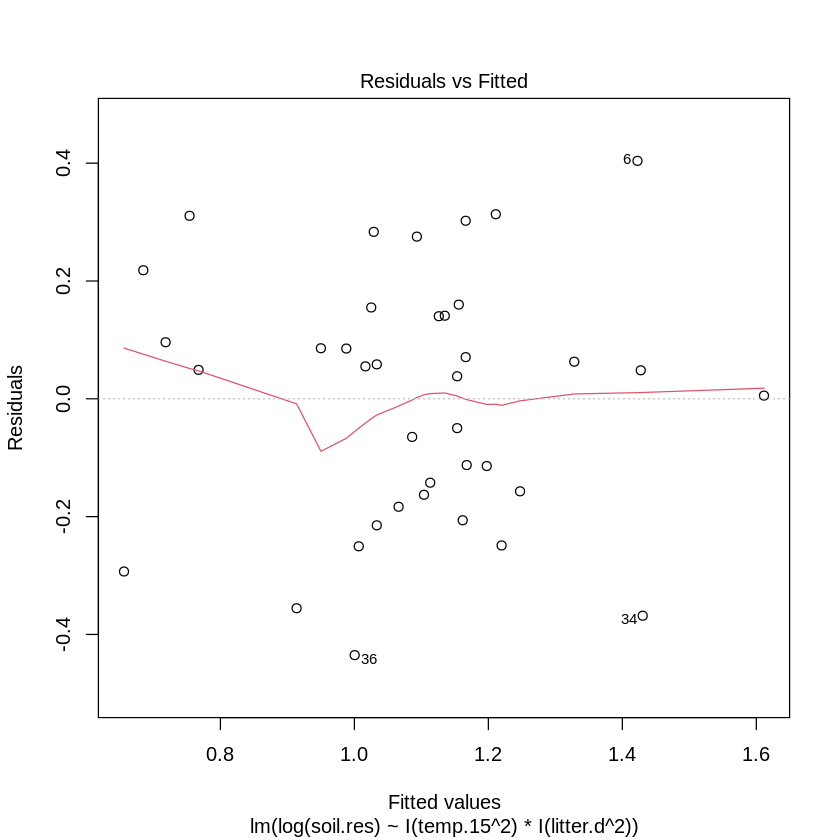

In [60]:
#Zur Uebersicht (dem allgemeinen Verstaendnis)

# Diagnostikplots des Modells
# plot(best_model_regsubset, 1) residuenplot sieht scheiße aus
#plot(model_multi, 3) #scale location plot scheiße
plot(bester_model, 1)
plot(bester_model_wI, 1) #residuenplot sieht scheiße aus
#plot(full_model, 1) residuenplot sieht scheiße aus
#plot(model2, 1) residuenplot sieht scheiße aus
#plot(model_diss_I1, 1)
#plot(model_diss_I2, 1)

# Modelluebersicht
#summary(bester_model), alle werte signifikant
#summary(model_diss), nur lmoi signifikant
#summary(model_multi)
#R nahe beieinander

#Vergleich der finalen Modelle ueber BIC
#BIC(bester_model)
#BIC(model_diss)

In [62]:
#LOOCV: Modell wird n-mal geschaetzt, jeweils eine Beobachtung weggelassen
#je kleiner, desto besser
cv_rmse_loocv <- function(formula, data){
  glm.fit <- glm(formula, data = data)
  cv.out <- cv.glm(data, glm.fit)
  sqrt(cv.out$delta[1])
}

#k-fold Cross Validation: Datensatz wird in k Teile aufgeteilt
#ebenso je kleiner, desto besser
cv_rmse_kfold <- function(formula, data, K = 10){
  glm.fit <- glm(formula, data = data)
  cv.out <- cv.glm(data, glm.fit, K = K)
  sqrt(cv.out$delta[1])
}

#LOOCV-RMSE fuer beide Modelle
rmse_loocv_best <- cv_rmse_loocv(formula(bester_model), hainich.data)
rmse_loocv_big1  <- cv_rmse_loocv(formula(bester_model_wI), hainich.data)

#10-fold-CV-RMSE fuer beide Modelle
rmse_kfold_best <- cv_rmse_kfold(formula(bester_model), hainich.data, K = 10)
rmse_kfold_big1  <- cv_rmse_kfold(formula(bester_model_wI), hainich.data, K = 10)


#Ausgabe der Ergebnisse

cat("LOOCV RMSE (best_model):", rmse_loocv_best, "\n")
cat("LOOCV RMSE (bester_model):", rmse_loocv_big1, "\n\n")

cat("10-fold CV RMSE (best_model):", rmse_kfold_best, "\n")
cat("10-fold CV RMSE (bester_model):", rmse_kfold_big, "\n\n")

# bester model ist besser aber nur knapp
'LOOCV RMSE (best_model): 0.245251 
LOOCV RMSE (model_big): 0.2688777 

10-fold CV RMSE (best_model): 0.2449544 
10-fold CV RMSE (model_big): 0.2774189'

LOOCV RMSE (best_model): 0.245251 
LOOCV RMSE (bester_model): 0.2415569 

10-fold CV RMSE (best_model): 0.2463758 
10-fold CV RMSE (bester_model): 0.2711378 



[1] "LOOCV RMSE (best_model): 0.245251 \nLOOCV RMSE (model_big): 0.2688777 \n\n10-fold CV RMSE (best_model): 0.2449544 \n10-fold CV RMSE (model_big): 0.2774189"

In [63]:
#Test auf Normalverteilung Residuen
#mit shapiro wilk test
#reduziertes mdoel
# W sollte nahe 1 sein, für Normalverteilung
print(shapiro.test(residuals(bester_model)))

#test auf konstante Varianz residuen
#breusch pagan test: Tests zur Pruefung von Heteroskedastizitaet.
#reduziertes modell
# wenn p-Wert signifikant ist das Hinweis für Heterokedastizität, die wollen wir nicht haben!
print(bptest(bester_model))

#model_big: shapiro
print(shapiro.test(residuals(bester_model_wI)))
#model_big:breusch
print(bptest(bester_model_wI))

#model_diss besser normalverteilt
#beide modelle haben heterokedastizität!

'Shapiro-Wilk normality test

data:  residuals(bester_model)
W = 0.94857, p-value = 0.07991


	studentized Breusch-Pagan test

data:  bester_model
BP = 1.3345, df = 2, p-value = 0.5131


	Shapiro-Wilk normality test

data:  residuals(model_diss)
W = 0.9822, p-value = 0.7938


	studentized Breusch-Pagan test

data:  model_diss
BP = 4.6841, df = 4, p-value = 0.3213'


	Shapiro-Wilk normality test

data:  residuals(bester_model)
W = 0.94857, p-value = 0.07991


	studentized Breusch-Pagan test

data:  bester_model
BP = 1.3345, df = 2, p-value = 0.5131


	Shapiro-Wilk normality test

data:  residuals(bester_model_wI)
W = 0.97467, p-value = 0.5319


	studentized Breusch-Pagan test

data:  bester_model_wI
BP = 7.2935, df = 3, p-value = 0.06311



[1] "Shapiro-Wilk normality test\n\ndata:  residuals(bester_model)\nW = 0.94857, p-value = 0.07991\n\n\n\tstudentized Breusch-Pagan test\n\ndata:  bester_model\nBP = 1.3345, df = 2, p-value = 0.5131\n\n\n\tShapiro-Wilk normality test\n\ndata:  residuals(model_diss)\nW = 0.9822, p-value = 0.7938\n\n\n\tstudentized Breusch-Pagan test\n\ndata:  model_diss\nBP = 4.6841, df = 4, p-value = 0.3213"

 6 34 
 6 34 


[1] 0.1052632

[1] " 6 31 34 \n 6 31 34 \n\n0.105263157894737"

[1] "2 33 38 \n 2 33 38 \n\n0.105263157894737"

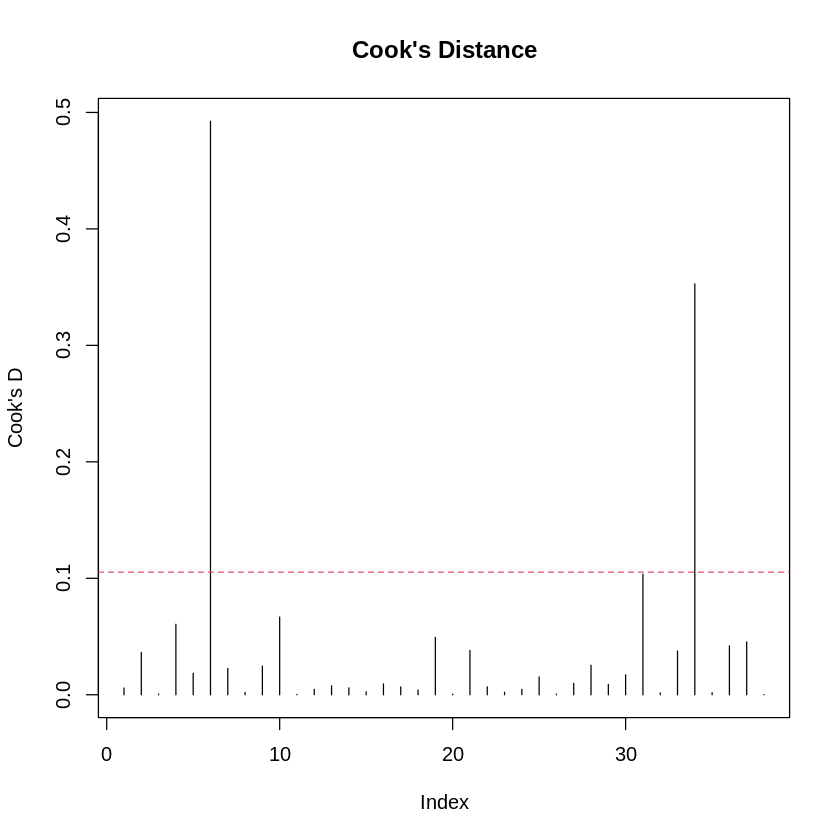

In [64]:
#beobachten (wichtige)
#cook's Distance misst Einfluss einzelner Beobachtungen
cook <- cooks.distance(bester_model_wI)

#typische Schwelle
cook.limit <- 4 / nrow(hainich.data)

print(which(cook > cook.limit))
cook.limit

#-> plots
#cooks distanz plot
plot(cook, type = "h",
     main = "Cook's Distance",
     ylab = "Cook's D")
abline(h = cook.limit, col = 2, lty = 2)

#bester model
' 6 31 34 
 6 31 34 

0.105263157894737'

#model diss
 '2 33 38 
 2 33 38 

0.105263157894737'